# 2.2 Threshold Tuning & Drift Analysis

คำถามที่ notebook นี้ตอบ (มุมมองทีม Compliance / AML):
1. **ควรตั้ง threshold เท่าไหร่?** — ค่า default 0.5 ไม่จำเป็นต้องดีที่สุด ในงาน AML การปล่อยธุรกรรมผิดกฎหมายหลุดไป (false negative) มักแพงกว่าการแจ้งเตือนเกิน
2. **ถ้าทีมตรวจได้แค่ K รายการ จะเจอของจริงกี่รายการ?** (Precision@K)
3. **โมเดลยังแม่นอยู่ไหมเมื่อเวลาผ่านไป?** (concept drift ราย time step)

> ใช้โมเดล V1 graph ที่ train จาก `2.0-model-training_v1.ipynb` และ test set เดียวกัน (time step 35–49)

In [1]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             precision_score, recall_score, f1_score)

plt.style.use('ggplot')
pd.set_option('display.float_format', '{:.3f}'.format)

## 1. Load data & models

In [2]:
df = pd.read_csv('../data/processed/elliptic_bitcoin_dataset_v1_graph.csv')
df = df.rename(columns={'feat_0': 'time_step'})
if 'class' in df.columns:
    df = df.drop(columns=['class'])

test_df = df[df['time_step'] > 34]
drop_cols = ['label', 'txId', 'time_step']
X_test = test_df.drop(columns=drop_cols)
y_test = test_df['label']
print(f"Test set: {X_test.shape}, illicit = {int(y_test.sum()):,}")

models = {}
for name, fn in {"Logistic Regression": "logistic_regression_smote_v1_graph.pkl",
                 "Random Forest": "random_forest_smote_v1_graph.pkl",
                 "XGBoost": "xgboost_smote_v1_graph.pkl"}.items():
    with open(os.path.join('../models', fn), 'rb') as f:
        models[name] = pickle.load(f)

probs = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

Test set: (16670, 167), illicit = 1,083


## 2. Precision–Recall curve

ข้อมูลไม่สมดุล (illicit ~6.5% ของ test set) จึงใช้ **PR curve / PR-AUC** แทน ROC-AUC — ROC ดูดีเกินจริงเมื่อ class ลบมีเยอะมาก

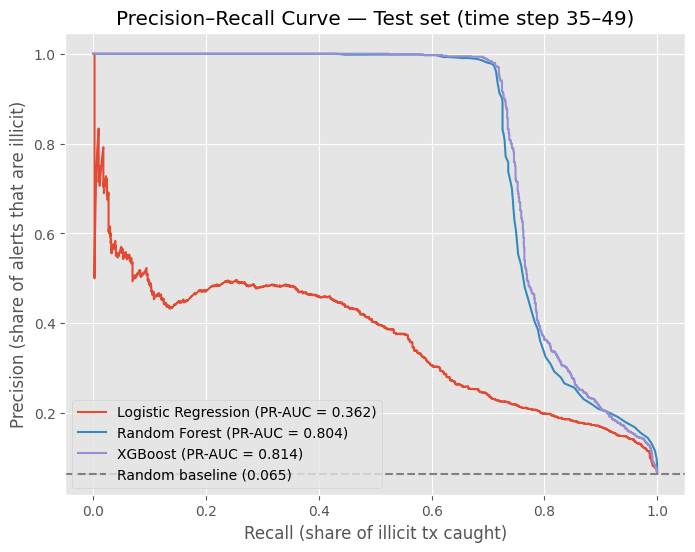

In [3]:
plt.figure(figsize=(8, 6))
for name, p in probs.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    ap = average_precision_score(y_test, p)
    plt.plot(rec, prec, label=f"{name} (PR-AUC = {ap:.3f})")
baseline = y_test.mean()
plt.axhline(baseline, ls='--', c='grey', label=f'Random baseline ({baseline:.3f})')
plt.xlabel('Recall (share of illicit tx caught)')
plt.ylabel('Precision (share of alerts that are illicit)')
plt.title('Precision–Recall Curve — Test set (time step 35–49)')
plt.legend(); plt.show()

## 3. Threshold sweep

เลือกโมเดลหลัก แล้วดูว่าแต่ละ threshold ได้ precision / recall / จำนวน alert เท่าไหร่

In [4]:
MAIN_MODEL = 'XGBoost'
p = probs[MAIN_MODEL]

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (p >= t).astype(int)
    rows.append({'threshold': round(t, 2),
                 'alerts': int(pred.sum()),
                 'precision': precision_score(y_test, pred, zero_division=0),
                 'recall': recall_score(y_test, pred, zero_division=0),
                 'f1': f1_score(y_test, pred, zero_division=0)})
sweep = pd.DataFrame(rows)

best_f1 = sweep.loc[sweep['f1'].idxmax()]
# จุดที่ recall >= 0.80 โดย precision สูงสุด (ตัวอย่าง policy: "ต้องจับให้ได้อย่างน้อย 80%")
target = sweep[sweep['recall'] >= 0.80]
best_recall80 = target.loc[target['precision'].idxmax()] if len(target) else None

print("Best F1 threshold:\n", best_f1, "\n")
print("Highest-precision threshold with recall >= 80%:\n", best_recall80)
sweep

Best F1 threshold:
 threshold     0.800
alerts      808.000
precision     0.964
recall        0.719
f1            0.824
Name: 15, dtype: float64 

Highest-precision threshold with recall >= 80%:
 None


,threshold,alerts,precision,recall,f1
0,0.050,1442,0.574,0.764,0.655
1,0.100,1217,0.672,0.755,0.711
2,0.150,1106,0.733,0.749,0.741
3,0.200,1047,0.772,0.746,0.759
4,0.250,1004,0.800,0.741,0.770
5,0.300,975,0.819,0.738,0.776
6,0.350,950,0.838,0.735,0.783
7,0.400,925,0.859,0.734,0.792
8,0.450,899,0.882,0.732,0.800
9,0.500,880,0.898,0.729,0.805


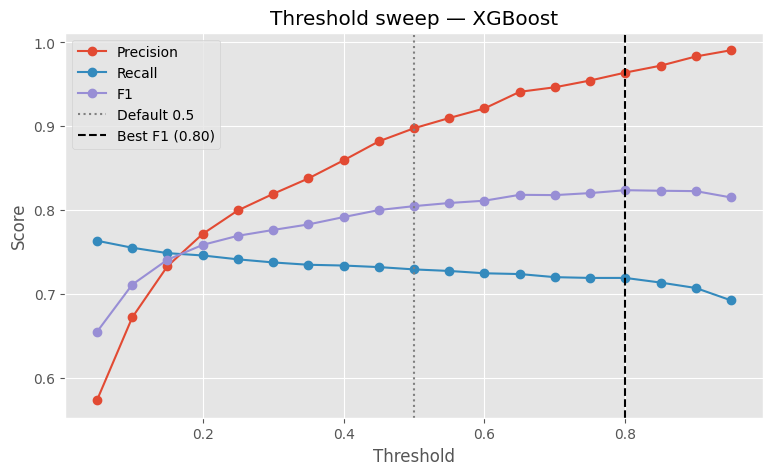

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sweep['threshold'], sweep['precision'], marker='o', label='Precision')
ax.plot(sweep['threshold'], sweep['recall'], marker='o', label='Recall')
ax.plot(sweep['threshold'], sweep['f1'], marker='o', label='F1')
ax.axvline(0.5, ls=':', c='grey', label='Default 0.5')
ax.axvline(best_f1['threshold'], ls='--', c='black', label=f"Best F1 ({best_f1['threshold']:.2f})")
ax.set_xlabel('Threshold'); ax.set_ylabel('Score'); ax.set_title(f'Threshold sweep — {MAIN_MODEL}')
ax.legend(); plt.show()

## 4. Precision@K — "ถ้าทีมตรวจได้แค่ K รายการ"

In [6]:
def precision_at_k(y_true, scores, ks=(100, 250, 500, 1000)):
    order = np.argsort(-scores)
    y_sorted = np.asarray(y_true)[order]
    total = y_sorted.sum()
    return pd.DataFrame([{'K': k,
                          'fraud_found': int(y_sorted[:k].sum()),
                          'precision@K': y_sorted[:k].mean(),
                          'share_of_all_fraud': y_sorted[:k].sum() / total} for k in ks])

pd.concat({name: precision_at_k(y_test, p) for name, p in probs.items()}, names=['model'])

K  fraud_found  precision@K  share_of_all_fraud
model                                                                    
Logistic Regression 0   100           56        0.560               0.052
                    1   250          116        0.464               0.107
                    2   500          242        0.484               0.223
                    3  1000          455        0.455               0.420
Random Forest       0   100          100        1.000               0.092
                    1   250          250        1.000               0.231
                    2   500          499        0.998               0.461
                    3  1000          791        0.791               0.730
XGBoost             0   100          100        1.000               0.092
                    1   250          250        1.000               0.231
                    2   500          500        1.000               0.462
                    3  1000          802        0.802               0.741

## 5. Performance by time step (concept drift)

Paper ต้นฉบับของ Elliptic (Weber et al., 2019) รายงานว่าหลัง **time step 43** มี dark market ขนาดใหญ่ถูกปิด
ทำให้รูปแบบธุรกรรมผิดกฎหมายเปลี่ยนไป และโมเดลที่ train จากข้อมูลก่อนหน้าจับได้แย่ลงมาก — มาดูว่าโมเดลของเราเจอปรากฏการณ์เดียวกันไหม

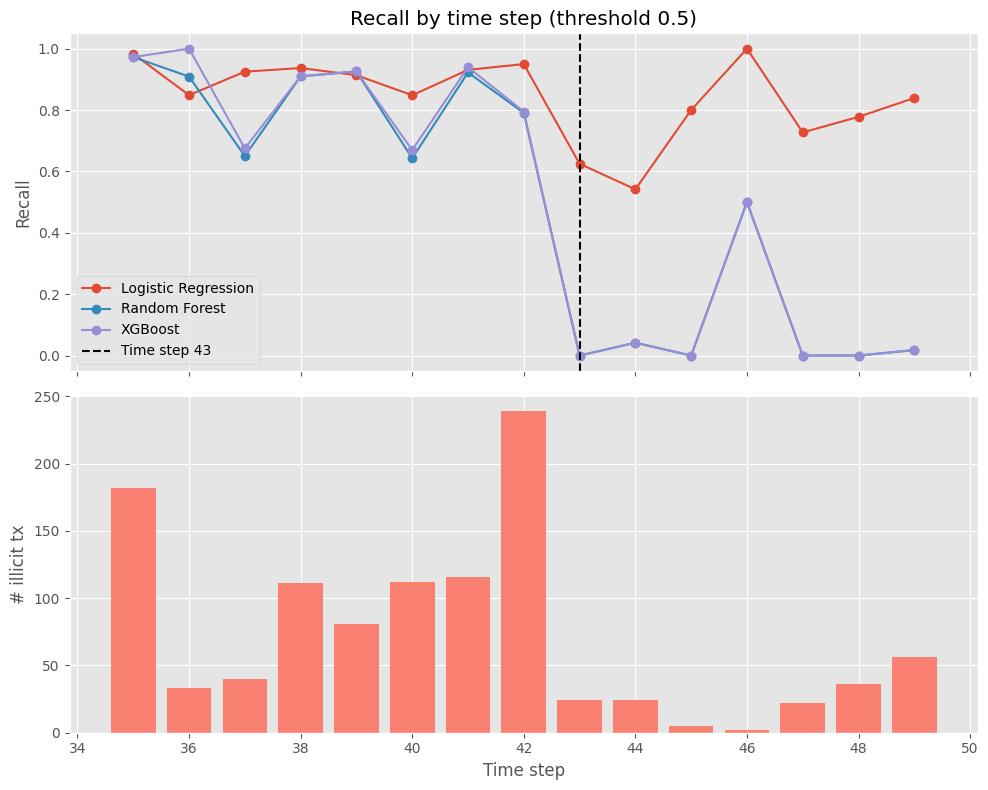

model,Logistic Regression,Random Forest,XGBoost
time_step,,,
35,0.984,0.973,0.973
36,0.848,0.909,1.000
37,0.925,0.650,0.675
38,0.937,0.910,0.910
39,0.914,0.926,0.926
40,0.848,0.643,0.670
41,0.931,0.922,0.940
42,0.950,0.791,0.795
43,0.625,0.000,0.000


In [7]:
THRESHOLD = 0.5  # ลองเปลี่ยนเป็น best_f1['threshold'] เพื่อเทียบ

rows = []
for name, m in models.items():
    for t, g in test_df.groupby('time_step'):
        pred = (m.predict_proba(g.drop(columns=drop_cols))[:, 1] >= THRESHOLD).astype(int)
        rows.append({'model': name, 'time_step': t, 'illicit': int(g['label'].sum()),
                     'recall': recall_score(g['label'], pred, zero_division=0),
                     'precision': precision_score(g['label'], pred, zero_division=0)})
by_t = pd.DataFrame(rows)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for name, g in by_t.groupby('model'):
    ax1.plot(g['time_step'], g['recall'], marker='o', label=name)
ax1.axvline(43, ls='--', c='black', label='Time step 43')
ax1.set_ylabel('Recall'); ax1.set_title(f'Recall by time step (threshold {THRESHOLD})'); ax1.legend()

counts = by_t.drop_duplicates('time_step')
ax2.bar(counts['time_step'], counts['illicit'], color='salmon')
ax2.set_xlabel('Time step'); ax2.set_ylabel('# illicit tx')
plt.tight_layout(); plt.show()

by_t.pivot(index='time_step', columns='model', values='recall')

In [8]:
before = by_t[by_t['time_step'] <= 43].groupby('model')['recall'].mean()
after = by_t[by_t['time_step'] > 43].groupby('model')['recall'].mean()
pd.DataFrame({'mean recall t35-43': before, 'mean recall t44-49': after, 'drop': before - after})

,mean recall t35-43,mean recall t44-49,drop
model,,,
Logistic Regression,0.885,0.781,0.104
Random Forest,0.747,0.093,0.654
XGBoost,0.765,0.093,0.672


## 6. สรุป (เขียนหลังรัน)

- Threshold ที่เลือก: ...
- Precision@K: ...
- Drift: ...
- ข้อเสนอแนะ: เช่น retrain เป็นระยะ / monitor recall รายสัปดาห์ / ใช้ threshold ต่างกันตามขนาดทีมตรวจ